# Button pressing

Loads `outputs/button_pressing/` and isolates each run's steady-state window.

Scripted: four strengths, five repeats each, identical goals — repeats give the error bar.
Position and strength are always read from the run itself, never the config.

**The arm leaves the y = 0 plane by up to 16 cm** (goal z locked, gravity along -y). One run
grazes the obstacle at 0.8 cm in x-z but is 12.2 cm away in 3-D, so the geometry figure shows
both projections plus the true 3-D distance, the one to compare against sigma.

Older runs carry a smaller field set; the cells below adapt to what's present.


In [1]:
import sys, os, importlib.util
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_1P5, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
from VMC_utils.ConfigHelpers import strip_repeat

# plot_config.py's COLORS is the repo-wide pastel palette (a later, unrelated
# change) -- but every figure already saved in this notebook was built with
# the ORIGINAL vivid "npg" palette (before that pastel-ization), so importing
# today's COLORS and re-running would silently repaint every existing plot
# here pastel. Overriding it locally keeps this notebook's figures matching
# what's already saved, independent of whatever plot_config.py defaults to
# later.
COLORS = ['#4DBBD5', '#E64B35', '#00A087', '#3C5488', '#F39B7F',
         '#8491B4', '#91D1C2', '#DC0000', '#7E6148', '#B09C85']

GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

import glob
import numpy as np
import matplotlib.pyplot as plt

G_TO_N = 9.80665e-3   # load cell reports grams
S_BACKBONE = np.linspace(0.0, 1.0, 25)
SETTLE_S = 1.0        # [s] dropped from the front of a hold window, to let the arm arrive


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the runs it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))


def nice(label):
    """Legend-ready text: no underscores, starts with a capital letter."""
    return label.replace('_', ' ').capitalize()

In [2]:
def load_cfg(name):
    """Import a config variant by file name without copying it into place."""
    spec = importlib.util.spec_from_file_location('cfg_' + name, f'GUI_MultiVMC_Config_{name}.py')
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def list_runs(folder):
    """Every run recorded in outputs/<folder>/, by name.

    A run that didn't exit cleanly can leave `<run>.autosave.npz` (last 30 s
    checkpoint, readable) or `<run>.npz.part.npz` (truncated, skipped)."""
    names = []
    for path in sorted(glob.glob(os.path.join('outputs', folder, '*.npz'))):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
            continue
        if name.endswith('.autosave'):
            print(f'[note] {name}.npz is a checkpoint: the run did not exit cleanly, '
                  'so it ends at the last one taken')
        names.append(name)
    return names


def hold_window(d, tol=1e-9, settle=SETTLE_S, mark_index=0):
    """The measurement window.

    With an operator mark (Ctrl+C when the tip reached the button), the window
    starts there and runs until something moves again; `mark_index` picks which
    mark. Without one, falls back to the longest stretch where nothing moved
    (goal x/y, spring/damper params) -- can't tell "on the button" from "let go
    of the mouse", and can span a mid-run stiffness change.

    Goal z is excluded from the motion check: in `_person`/`_card_castle`
    (GOAL_Z_TRACK) it re-tracks the attachment point every tick and wiggles at
    ~1e-5 m from FK noise even when still, which fragmented the hold into single
    ticks. `_button`'s locked z is unaffected either way.

    Drops the first SETTLE_S so the arm's arrival isn't averaged in."""
    t   = d['t']
    sig = [d['goal'][:, :, :2].reshape(len(t), -1), d['k_params']]
    if 'c_params' in d:
        sig.append(d['c_params'])
    sig = np.hstack([np.asarray(s, dtype=float) for s in sig])

    changed = np.r_[True, np.abs(np.diff(sig, axis=0)).max(axis=1) > tol]
    seg     = np.cumsum(changed)

    marks = np.asarray(d.get('marks_t', []), dtype=float)
    marks = marks[np.isfinite(marks) & (marks >= t[0]) & (marks <= t[-1])]
    if len(marks) > mark_index:
        m0   = marks[mark_index]
        hold = (seg == seg[int(np.searchsorted(t, m0))]) & (t >= m0)
    else:
        hold = seg == np.bincount(seg).argmax()

    trimmed = hold & (t >= t[hold][0] + settle) if hold.any() else hold
    return trimmed if trimmed.any() else hold   # a mark right before Ctrl+C


def load_run(folder, name):
    """One run: hold window marked, newer log channels passed through when present."""
    raw = np.load(os.path.join('outputs', folder, name + '.npz'), allow_pickle=True)
    d   = {k: raw[k] for k in raw.files}   # forces the read now, not lazily

    hold     = hold_window(d)
    tip_goal = d['goal'][:, 0, :]
    k_gauss  = d['k_params'][:, 1]

    r = dict(name=name, folder=folder, raw=d, t=d['t'], hold=hold,
             goal=d['goal'], comp_pos=d['comp_pos'],
             q_motor=d['q_motor'], tau=d['tau'],
             k_params=d['k_params'], k_gauss=k_gauss,
             force_n=d['force'] * G_TO_N,
             s_params=d['comp_s_params'],
             comp_names=[str(n) for n in d['comp_names']],
             tau_limit=float(d['tau_limit'][0]),
             strength=float(k_gauss[hold].mean()),
             target=tip_goal[hold].mean(axis=0),
             obstacle=d['goal'][hold, 1, :].mean(axis=0))

    # ── Channels only newer runs carry ────────────────────────────────────────
    r['f_comp']    = d.get('f_comp')            # (n, N_VC, 3) [N] per element
    r['comp_vel']  = d.get('comp_vel')          # (n, N_VC, 3) [m/s]
    r['c_params']  = d.get('c_params')
    r['force_age'] = d.get('force_age')
    r['tau_raw']   = d.get('tau_raw', d['tau'])  # pre-limiter torque, else the clipped one
    r['clipped']   = np.any(np.abs(r['tau_raw']) > r['tau_limit'] + 1e-12, axis=1)
    r['has_pre']   = bool((d['t'] < 0).any())    # logged before the GUI connected
    r['force_live'] = bool(np.any(d['force'] != 0.0))
    # Group repeats by condition (button: `weak_r1..r5`); a person/card_castle
    # run is one file per level, so it's its own group.
    r['condition']   = strip_repeat(name)
    r['repeat']      = name[len(r['condition']):].lstrip('_') or None
    r['marks_t']     = np.asarray(d.get('marks_t', []), dtype=float)
    r['marks_label'] = [str(x) for x in d.get('marks_label', [])]
    return r


def backbone(run, hold=None):
    """FK backbone at the mean pose over a window (the hold window by default)."""
    mask = run['hold'] if hold is None else hold
    q_ss = run['q_motor'][mask].mean(axis=0)
    return np.array([FK_Multi(q_ss, s)[:3] for s in S_BACKBONE])


def load_all(folder):
    """Every readable run in a folder; one bad file doesn't stop the rest."""
    runs = []
    for name in list_runs(folder):
        try:
            runs.append(load_run(folder, name))
        except Exception as exc:
            print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')
    # Sweep order, not alphabetical -- `medium_r1` would sort before `no_gauss_r1`
    # and reverse the legend. Runs at one strength (person/card_castle) just sort by name.
    return sorted(runs, key=lambda r: (r['strength'], r['name']))


def summary(runs):
    for r in runs:
        b   = backbone(r)
        clr = np.linalg.norm(b - r['obstacle'], axis=1).min()
        tip = r['comp_pos'][r['hold'], 0, :].mean(axis=0)
        r['clearance']   = float(clr)
        r['reach_error'] = float(np.linalg.norm(r['target'] - tip))
        t = r['t'][r['hold']]
        print(f"{r['name']:>14}  strength {r['strength']:6.0f}  "
              f"hold {t[0]:6.1f}-{t[-1]:6.1f}s ({r['hold'].sum():6d} samples)  "
              f"clearance {clr*100:5.1f} cm  reach err {r['reach_error']*100:5.1f} cm  "
              f"clip {100*r['clipped'][r['hold']].mean():4.0f}%  "
              f"force {'live' if r['force_live'] else 'FLAT'}  "
              f"window {'marked' if len(r['marks_t']) else 'inferred'}")


def repeat_mean_std(group, col='force_n', n_pts=2000, t_max=None):
    """Interpolate `col` from every repeat in a condition onto one shared time
    grid (t=0 at each run's own start) and return (t_grid, mean, std, per-repeat
    array) -- repeats don't share sample counts or exact timestamps, so a plain
    stack-and-average would misalign them."""
    ts = [r['t'] - r['t'][0] for r in group]
    ys = [r[col] for r in group]
    hi = t_max if t_max is not None else min(t[-1] for t in ts)
    t_grid = np.linspace(0.0, hi, n_pts)
    vals = np.array([np.interp(t_grid, t, y) for t, y in zip(ts, ys)])
    return t_grid, vals.mean(axis=0), vals.std(axis=0), vals

In [3]:
cfg_b  = load_cfg('button')
runs_b = load_all('button_pressing')
if not runs_b:
    print('outputs/button_pressing/ is empty -- record the button runs first '
          '(README: python3 run_sweep.py).')
else:
    summary(runs_b)

   no_gauss_r1  strength      0  hold   56.2-  75.2s (  6253 samples)  clearance   2.2 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r2  strength      0  hold   56.2-  75.2s (  6253 samples)  clearance   2.1 cm  reach err  23.0 cm  clip    0%  force live  window marked
   no_gauss_r3  strength      0  hold   56.2-  75.2s (  6258 samples)  clearance   2.3 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r4  strength      0  hold   56.2-  75.2s (  6264 samples)  clearance   2.2 cm  reach err  23.1 cm  clip    0%  force live  window marked
   no_gauss_r5  strength      0  hold   56.2-  75.2s (  6251 samples)  clearance   2.2 cm  reach err  23.0 cm  clip    0%  force live  window marked
       weak_r1  strength    200  hold   56.2-  75.1s (  6236 samples)  clearance   6.1 cm  reach err  27.6 cm  clip    0%  force live  window marked
       weak_r2  strength    200  hold   56.2-  75.2s (  6264 samples)  clearance   6.2 cm  reach err  27.6

### Shear force by condition

The only channel worth a per-run look here is the load cell. One pair of figures per
condition — the whole run and the first 65 s — with the 5 repeats shown faint behind
their mean and ±1 std band, all on the same time and force scale so the four conditions
compare directly. Time is zero at each run's own start.

In [4]:
PLOT_SHEAR = False   # TUNE THIS: True = draw, show and save the 8 shear figures; False (default) = skip them
SHEAR_WIDTH = FIG_W_1P5   # in -- TUNE THIS: figure width
SHEAR_ASPECT_W, SHEAR_ASPECT_H = 10, 7   # TUNE THIS: width:height ratio, as two integers

def plot_shear_by_condition(runs, folder, zoom_s=65.0, n_pts=2000):
    """Shear force only: one pair of figures per condition (whole run, first
    `zoom_s` s), repeats faint behind the mean +/- std band -- same style and
    y-scale throughout, so the four conditions compare directly."""
    live = [r for r in runs if r['force_live']]
    if not live:
        print('No run has a live load-cell channel -- nothing to plot.')
        return

    by_cond = {}
    for r in live:
        by_cond.setdefault(r['condition'], []).append(r)
    conds = sorted(by_cond, key=lambda c: by_cond[c][0]['strength'])

    t_max = min(r['t'][-1] - r['t'][0] for group in by_cond.values() for r in group)

    # One y-scale for every condition and both time windows.
    all_force = np.concatenate([r['force_n'] for group in by_cond.values() for r in group])
    pad = 0.08 * (all_force.max() - all_force.min())
    ylim = (min(0.0, all_force.min() - pad), all_force.max() + pad)

    shear_h = SHEAR_WIDTH * SHEAR_ASPECT_H / SHEAR_ASPECT_W
    for cond in conds:
        group    = by_cond[cond]
        strength = group[0]['strength']
        i        = conds.index(cond)
        t_grid, mean, std, vals = repeat_mean_std(group, t_max=t_max, n_pts=n_pts)
        hold_lo = np.mean([r['t'][r['hold']][0]  - r['t'][0] for r in group])
        hold_hi = np.mean([r['t'][r['hold']][-1] - r['t'][0] for r in group])

        for window_hi, tag in ((t_max, 'full'), (min(zoom_s, t_max), 'zoom')):
            fig, ax = plt.subplots(figsize=(SHEAR_WIDTH, shear_h), layout='constrained')
            mask = t_grid <= window_hi
            for v in vals:
                ax.plot(t_grid[mask], v[mask], color=COLORS[i], alpha=0.15, linewidth=1)
            ax.plot(t_grid[mask], mean[mask], color=COLORS[i], linewidth=2.5,
                    label=f'A: {strength:.0f} N')
            ax.fill_between(t_grid[mask], (mean - std)[mask], (mean + std)[mask],
                            color=COLORS[i], alpha=0.18, linewidth=0)
            ax.axvspan(hold_lo, hold_hi, color=COLORS[2], alpha=0.08, linewidth=0, zorder=0)
            ax.set_xlim(0, window_hi)
            ax.set_ylim(*ylim)
            ax.set_xlabel('Time (s)')
            ax.set_ylabel('Shear force (N)')
            ax.grid(GRID)
            ax.legend(fontsize=10, loc='lower right')
            save_fig(fig, folder, f'shear_{cond}_{tag}')
            plt.show()


if not PLOT_SHEAR:
    print('Shear figures skipped (PLOT_SHEAR = False).')
elif runs_b:
    plot_shear_by_condition(runs_b, 'button_pressing')

Shear figures skipped (PLOT_SHEAR = False).


### Geometry

The backbone's side view (X-Z) at each condition's steady pose, against the obstacle and
the target.

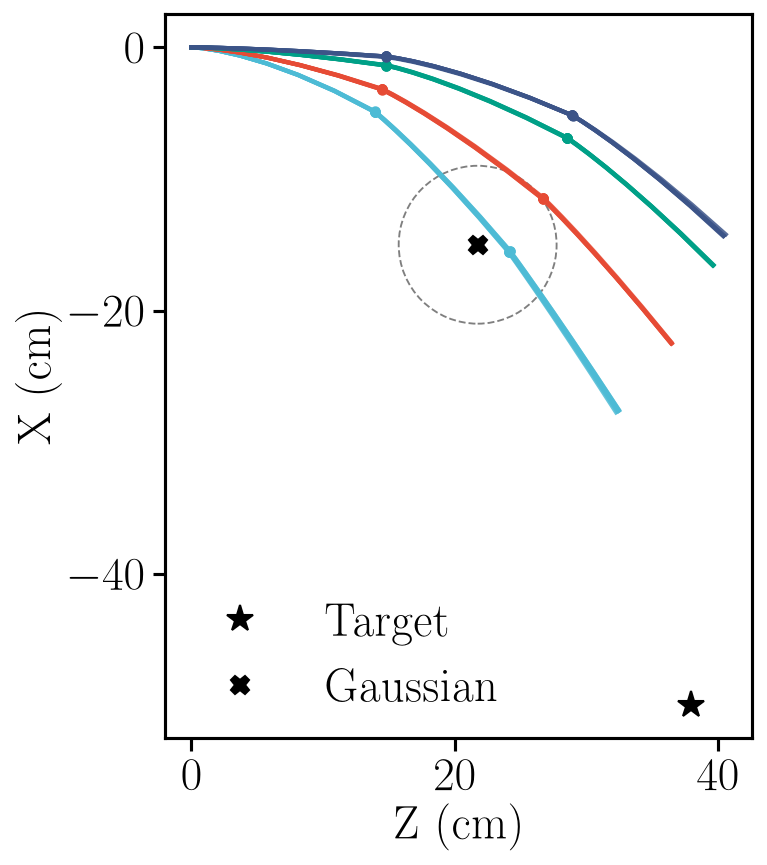

In [5]:
# Every X-Z figure (this combined one and the four single ones in the next cell) is drawn at
# EQUAL SCALE: 1 cm along Z is the same length on the page as 1 cm along X, so the sigma circle
# is a circle and angles are true. The panel therefore takes the shape of its data range;
# xz_figure sizes the canvas from it, so BACKBONE_WIDTH / SINGLE_WIDTH set the width and the
# height follows. The four single figures share one data range, so they come out identical.
from matplotlib.ticker import MultipleLocator
COMBINED_X_TICK_CM = 20   # TUNE THIS: X tick spacing of the combined figure (0, -20, -40)

def xz_figure(width_in, xlim, ylim):
    """Canvas + axes for one X-Z figure at equal scale. `xlim` is the horizontal (Z) range and
    `ylim` the vertical (X) range, both in cm. The canvas is made taller than the panel needs so
    the panel is limited by its width (`width_in` less the label margins); the repo-wide
    tight-bbox savefig crops the spare blank."""
    fig, ax = plt.subplots(
        figsize=(width_in, width_in * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0]) + 1.5),
        layout='constrained')
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect('equal', adjustable='box')
    return fig, ax


def _combined_bounds(runs, cfg, margin=0.05):
    """Z/X bounding box (cm) of the combined figure: every backbone, the obstacle's sigma
    circle and the target, plus `margin` of the range on each side."""
    obs, tgt = runs[0]['obstacle'], runs[0]['target']
    sig = cfg.SIGMA * 100
    zs = [obs[2] * 100 - sig, obs[2] * 100 + sig, tgt[2] * 100]
    xs = [obs[0] * 100 - sig, obs[0] * 100 + sig, tgt[0] * 100]
    for r in runs:
        b = backbone(r)
        zs.extend(b[:, 2] * 100)
        xs.extend(b[:, 0] * 100)
    z_pad = margin * (max(zs) - min(zs))
    x_pad = margin * (max(xs) - min(xs))
    return (min(zs) - z_pad, max(zs) + z_pad), (min(xs) - x_pad, max(xs) + x_pad)

BACKBONE_FONT        = 22.5  # TUNE THIS: tick/axis-label size
BACKBONE_LEGEND_FONT = BACKBONE_FONT  # TUNE THIS: legend text size (as big as the X and Z labels)
BACKBONE_WIDTH = 5   # in -- TUNE THIS: figure width; the height follows from equal scale

def plot_geometry(runs, cfg, folder, obstacle_label='Gaussian', name='backbone'):
    fig, ax = xz_figure(BACKBONE_WIDTH, *_combined_bounds(runs, cfg))

    obs = runs[0]['obstacle']
    tgt = runs[0]['target']
    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, not by file
        b   = backbone(r)
        # Z horizontal, X vertical -- same placement as the single-backbone
        # figures below (own range/size here though, not shared with those).
        ax.plot(b[:, 2] * 100, b[:, 0] * 100, color=COLORS[i], linewidth=2.0,
                alpha=0.85, zorder=3)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax.plot(p[2] * 100, p[0] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)

    ax.plot(tgt[2] * 100, tgt[0] * 100, '*', color='k', markersize=13, zorder=5, label='Target')
    ax.plot(obs[2] * 100, obs[0] * 100, 'X', color='k', markersize=9, zorder=5,
            label=nice(obstacle_label))
    # The true silhouette of a sphere of radius sigma -- and the trap: a
    # backbone drawn inside it is not necessarily within sigma in 3-D. The axes
    # are at equal scale, so this is a true circle.
    ax.add_patch(plt.Circle((obs[2] * 100, obs[0] * 100), cfg.SIGMA * 100, fill=False,
                            linestyle='--', color='k', linewidth=0.9, alpha=0.5, zorder=2))
    ax.set_xlabel('Z (cm)', fontsize=BACKBONE_FONT)
    ax.set_ylabel('X (cm)', fontsize=BACKBONE_FONT)
    # Equal scale (set in xz_figure): the panel's shape is the Z/X data range's.
    ax.tick_params(labelsize=BACKBONE_FONT)
    ax.yaxis.set_major_locator(MultipleLocator(COMBINED_X_TICK_CM))   # X is the vertical axis here
    ax.grid(GRID)
    ax.legend(fontsize=BACKBONE_LEGEND_FONT, loc='best', framealpha=0.9)

    save_fig(fig, folder, name)
    plt.show()


if runs_b:
    plot_geometry(runs_b, cfg_b, 'button_pressing', obstacle_label='Gaussian')

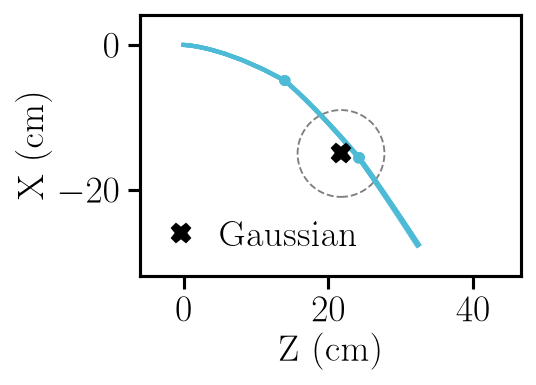

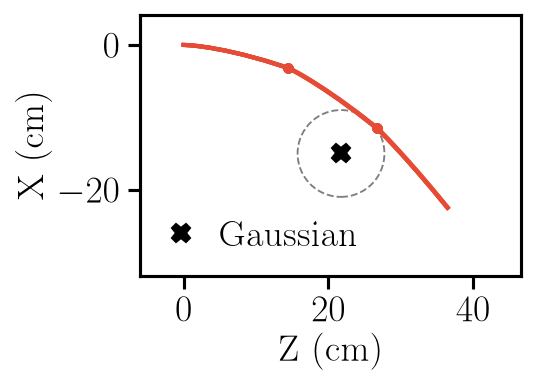

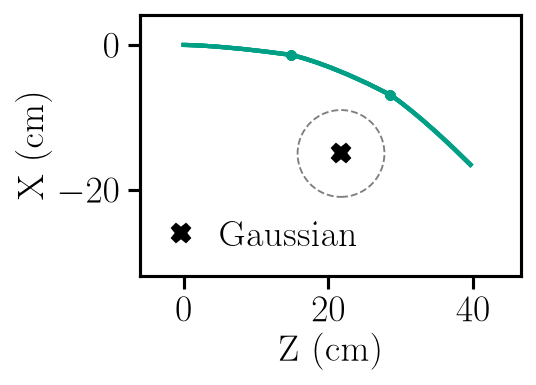

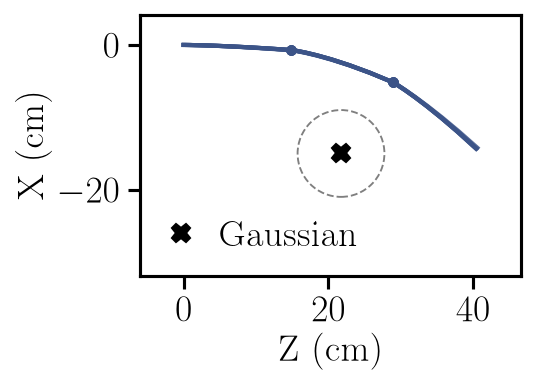

In [6]:
SINGLE_WIDTH = FIG_W_SINGLE   # in -- TUNE THIS: figure width
SINGLE_LEGEND_FONT = FONT_SIZE   # TUNE THIS: "Gaussian" legend text size (as big as the X and Z labels, which use FONT_SIZE)

def _geometry_bounds(runs, cfg, conds, margin=0.15):
    """Z/X bounding box (cm), pooled across every condition in `conds` --
    every single-backbone figure sharing this box (with the same figsize) is
    what actually makes them come out the same size."""
    zs, xs = [], []
    for cond in conds:
        obs = next(r['obstacle'] for r in runs if r['condition'] == cond)
        zs += [obs[2] * 100 - cfg.SIGMA * 100, obs[2] * 100 + cfg.SIGMA * 100]
        xs += [obs[0] * 100 - cfg.SIGMA * 100, obs[0] * 100 + cfg.SIGMA * 100]
        for r in runs:
            if r['condition'] != cond:
                continue
            b = backbone(r)
            zs.extend(b[:, 2] * 100)
            xs.extend(b[:, 0] * 100)
    z_lo, z_hi = min(zs), max(zs)
    x_lo, x_hi = min(xs), max(xs)
    z_pad = margin * (z_hi - z_lo)
    x_pad = margin * (x_hi - x_lo)
    return (z_lo - z_pad, z_hi + z_pad), (x_lo - x_pad, x_hi + x_pad)


def plot_geometry_single(runs, cfg, folder, condition, color, xlim, ylim,
                         obstacle_label='Gaussian', name=None):
    """One condition's backbone(s) only -- no Target marker (it sits far
    outside the obstacle/backbone region and was forcing a lot of empty
    space into the frame); legend is just the Gaussian. Axes swapped from
    the combined plot above: Z horizontal, X vertical. xlim/ylim are shared
    across all four calls (see _geometry_bounds) so every figure -- same
    width, same data range -- renders at the same size.

    Equal scale, as in the combined plot (see xz_figure in the cell above):
    1 cm in Z is the same length as 1 cm in X, so the sigma circle is a circle."""
    fig, ax = xz_figure(SINGLE_WIDTH, xlim, ylim)

    obs = runs[0]['obstacle']
    for r in runs:
        if r['condition'] != condition:
            continue
        b = backbone(r)
        ax.plot(b[:, 2] * 100, b[:, 0] * 100, color=color, linewidth=2.0,
                alpha=0.85, zorder=3)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax.plot(p[2] * 100, p[0] * 100, 'o', color=color, markersize=4, zorder=4)

    ax.plot(obs[2] * 100, obs[0] * 100, 'X', color='k', markersize=9, zorder=5,
            label=nice(obstacle_label))
    # The true silhouette of a sphere of radius sigma -- and the trap: a
    # backbone drawn inside it is not necessarily within sigma in 3-D.
    ax.add_patch(plt.Circle((obs[2] * 100, obs[0] * 100), cfg.SIGMA * 100, fill=False,
                            linestyle='--', color='k', linewidth=0.9, alpha=0.5, zorder=2))
    ax.set_xlabel('Z (cm)'); ax.set_ylabel('X (cm)')
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.grid(GRID)
    # Lower left, not 'best': at label size the legend is wide, and 'best' parked it against the tip
    # of the curve. That corner is clear in all four (they share one frame); the short handle
    # (a single marker) keeps the legend narrow so the text stays clear of the curve.
    ax.legend(fontsize=SINGLE_LEGEND_FONT, loc='lower left', framealpha=0.9,
              handlelength=1.0, handletextpad=0.5)

    save_fig(fig, folder, name or f'backbone_{condition}')
    plt.show()


# Four separate figures, one per condition (no_gauss/weak/medium/strong) --
# same per-condition color as the combined plot above (so a reader can match
# a single-backbone figure back to its color in that one), and the same
# shared xlim/ylim (so all four are the same size and shape).
if runs_b:
    conds_b = sorted({r['condition'] for r in runs_b},
                     key=lambda c: next(x['strength'] for x in runs_b if x['condition'] == c))
    xlim_b, ylim_b = _geometry_bounds(runs_b, cfg_b, conds_b)
    for i, cond in enumerate(conds_b):
        plot_geometry_single(runs_b, cfg_b, 'button_pressing', cond,
                             color=COLORS[i], xlim=xlim_b, ylim=ylim_b,
                             obstacle_label='Gaussian')

### Contact force

Only meaningful where the load cell was publishing — without `arduino_force.py` the channel
is all zeros (flat line, not "nothing"). It publishes `-force_shear`, so check the sign.

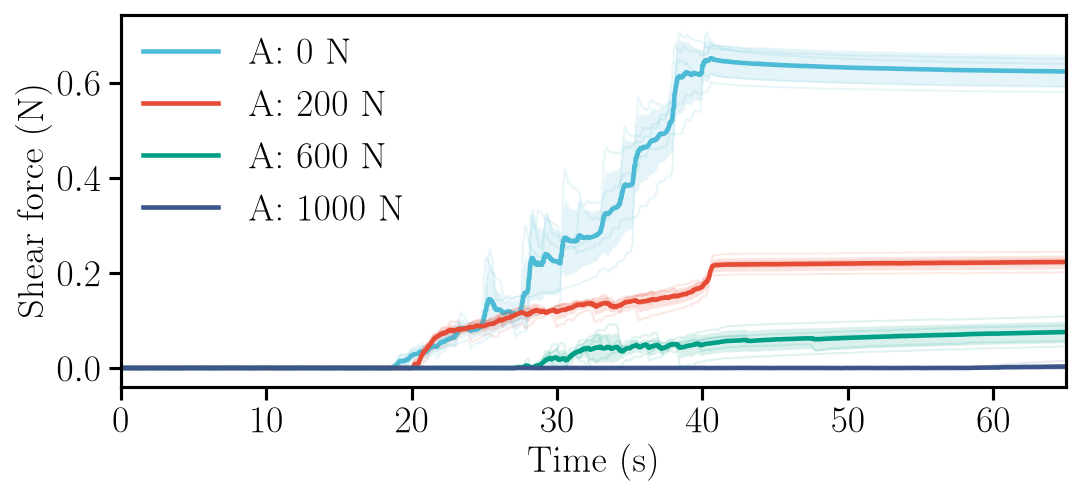

In [7]:
FORCE_TIME_WIDTH = FIG_W_DOUBLE   # in -- TUNE THIS: figure width
FORCE_TIME_ASPECT_W, FORCE_TIME_ASPECT_H = 20, 9   # TUNE THIS: width:height ratio, as two integers
FORCE_TIME_MAX_S = 65.0   # s -- TUNE THIS: right edge of the time axis (the runs are ~75 s; same 65 s as the shear zoom)

live_b = [r for r in runs_b if r['force_live']]
if not runs_b:
    print('outputs/button_pressing/ is empty -- nothing to plot.')
elif not live_b:
    print('No run in button_pressing has a live load-cell channel -- '
          'force is identically zero in: ' + ', '.join(r['name'] for r in runs_b))
else:
    # Mean +/- std across repeats per condition, repeats shown faint behind --
    # same style as the shear-by-condition figures above, all four overlaid.
    by_cond = {}
    for r in live_b:
        by_cond.setdefault(r['condition'], []).append(r)
    conds = sorted(by_cond, key=lambda c: by_cond[c][0]['strength'])
    t_max = min(r['t'][-1] - r['t'][0] for group in by_cond.values() for r in group)
    t_max = min(t_max, FORCE_TIME_MAX_S)

    fig, ax = plt.subplots(figsize=(FORCE_TIME_WIDTH, FORCE_TIME_WIDTH * FORCE_TIME_ASPECT_H / FORCE_TIME_ASPECT_W),
                           layout='constrained')
    for cond in conds:
        group = by_cond[cond]
        i     = conds.index(cond)
        t_grid, mean, std, vals = repeat_mean_std(group, t_max=t_max)
        for v in vals:
            ax.plot(t_grid, v, color=COLORS[i], alpha=0.12, linewidth=1)
        ax.plot(t_grid, mean, color=COLORS[i], linewidth=2.2,
                label=f"A: {group[0]['strength']:.0f} N")
        ax.fill_between(t_grid, mean - std, mean + std, color=COLORS[i], alpha=0.15, linewidth=0)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Shear force (N)')
    ax.set_xlim(0, t_max)
    ax.grid(GRID)
    ax.legend(fontsize=FONT_SIZE)   # same size as the axis labels
    save_fig(fig, 'button_pressing', 'force_vs_time')
    plt.show()


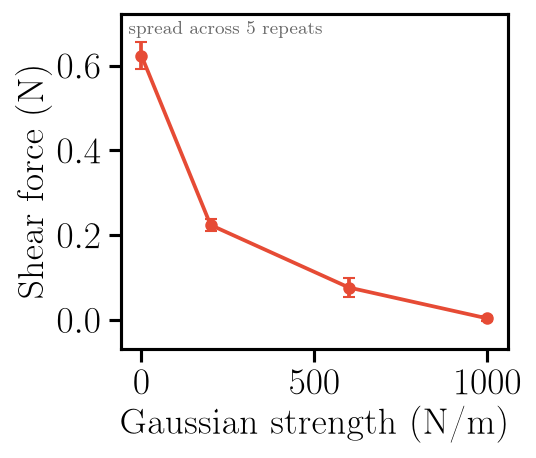

In [8]:
FORCE_STRENGTH_WIDTH = FIG_W_SINGLE   # in -- TUNE THIS: figure width
FORCE_STRENGTH_ASPECT_W, FORCE_STRENGTH_ASPECT_H = 20, 17   # TUNE THIS: width:height ratio, as two integers

# Steady-state contact force against Gaussian strength.
# With repeats, each condition contributes several recordings: the point is the
# mean across them and the bar their spread, which is what a repeated sweep is
# for. Without repeats it falls back to the within-window spread of the one run.
if len(live_b) < 2:
    print(f'{len(live_b)} run(s) with a live load cell -- nothing to sweep yet.')
else:
    by_cond = {}
    for r in live_b:
        by_cond.setdefault(r['condition'], []).append(r['force_n'][r['hold']].mean())
    conds    = sorted(by_cond, key=lambda c: next(r['strength'] for r in live_b
                                                  if r['condition'] == c))
    strength = np.array([next(r['strength'] for r in live_b if r['condition'] == c)
                         for c in conds])
    f_mean   = np.array([np.mean(by_cond[c]) for c in conds])
    n_rep    = np.array([len(by_cond[c]) for c in conds])
    if (n_rep > 1).any():
        f_err = np.array([np.std(by_cond[c]) for c in conds])
        note  = ('spread across %d repeats' % n_rep.min() if n_rep.min() == n_rep.max()
                 else f'spread across {n_rep.min()}-{n_rep.max()} repeats')
    else:
        f_err = np.array([r['force_n'][r['hold']].std()
                          for c in conds for r in live_b if r['condition'] == c])
        note  = 'within-window spread (1 run per condition)'

    fig, ax = plt.subplots(
        figsize=(FORCE_STRENGTH_WIDTH, FORCE_STRENGTH_WIDTH * FORCE_STRENGTH_ASPECT_H / FORCE_STRENGTH_ASPECT_W),
        layout='constrained')
    ax.errorbar(strength, f_mean, yerr=f_err, marker='o', color=COLORS[1],
                linewidth=1.8, markersize=5, capsize=3)
    ax.set_xlabel(r'Gaussian strength (N/m)')
    ax.set_ylabel('Shear force (N)')
    # Explicit padding on every side -- with layout='constrained' and limits
    # pinned exactly to the data, the errorbar caps at the first/last point and
    # at the top of the tallest bar were clipped right at the spine.
    x_pad = 0.06 * strength.max()
    y_lo  = min(0.0, (f_mean - f_err).min())
    y_hi  = (f_mean + f_err).max()
    y_pad = 0.10 * (y_hi - y_lo)
    ax.set_xlim(-x_pad, strength.max() + x_pad)
    ax.set_ylim(y_lo - y_pad, y_hi + y_pad)
    ax.grid(GRID)
    # Spread-type note as an in-panel annotation, not a title.
    ax.text(0.02, 0.98, note, transform=ax.transAxes, ha='left', va='top',
            fontsize=9, color='0.4')
    save_fig(fig, 'button_pressing', 'force_vs_strength')
    plt.show()